In [ ]:
from network_expansion import *
from externalize_results import *
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite
import numpy as np
from matplotlib.colors import Normalize, to_hex, BoundaryNorm
import matplotlib
import netwulf as nw
from netgraph import Graph, get_multipartite_layout

# Expansions from primordial seed sets
write_outputs = True
max_generation = 1000
name = 'primordial'

# define chemical scope
reaction_scope = get_sides(import_reaction_file())
compound_scope = set.union(*reaction_scope.stack())
seed_scope = seed_candidates.loc[seed_candidates.index.isin(compound_scope)]
seeds = list(seed_scope.index)

# run network expansion
result = expand_from_seed_set(seeds=seeds, reactions=reaction_scope, max_gen=max_generation)
write_expansion_csv(result, filename=name, destination_dir='Output/'+name+'/')
result = generate_annotated_bipartite_edge_list(result)
# summary = result
transition_gen = result['chiral_fraction'].where(lambda x: x>0.5).idxmin()
print(f"Transition Step: {transition_gen}")
#transition_gen = 10
transition_edge_df = result['bipartite_edgelist'].query('step <= @transition_gen').copy(deep=True)
print(transition_edge_df)
networks = {i: nx.from_pandas_edgelist(transition_edge_df[transition_edge_df[i]], 
        source='source', target='target', edge_attr=True, create_using=nx.DiGraph())
        for i in ['impactful_precursor','directed']} #immediate precursor
compound_nodes = {i: [l for l in bipartite.sets(networks[i]) if list(l)[0].startswith('C')][0] for i in networks.keys()}
networks_uni = {i: bipartite.projected_graph(networks[i], nodes=compound_nodes[i]) for i in networks.keys()}


/Users/csm/Desktop/chir_exp/ChiralExpansion/Code/network_expansion.py:15: DtypeWarning: Columns (3,4,5,6,7,8,10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(fpath, index_col=0)
/Users/csm/Desktop/chir_exp/ChiralExpansion/Code/network_expansion.py:62: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rns = pd.DataFrame(rns).replace(False, float('nan')).dropna(how='all').fillna(False).T.cummax().T
/Users/csm/Desktop/chir_exp/ChiralExpansion/Code/network_expansion.py:63: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)

Transition Step: 6
        directed  backward  step reaction   source   target  reaction_step  \
0          False     False     1   R00004   C00001   R00004            1.0   
1          False     False     1   R00004   C00013   R00004            1.0   
2          False     False     1   R00004   R00004   C00009            1.0   
3           True      True     1   R00005   C00011   R00005            1.0   
4           True      True     1   R00005   C00014   R00005            1.0   
...          ...       ...   ...      ...      ...      ...            ...   
432426      True     False     6  A148871  A148871   C16418            6.0   
432427      True     False     6  A148872   C09826  A148872            6.0   
432428      True     False     6  A148872   C14567  A148872            6.0   
432429      True     False     6  A148872  A148872   C10453            6.0   
432430      True     False     6  A148872  A148872   C16418            6.0   

        source_step  target_step  impactful_

In [2]:
def gna(G, attr): return nx.get_node_attributes(G, attr)

def colorize_Series(S, cmap='cet_CET_C6s'):
    # S should be list-like, or a dict, or a series.... of numbers.
    color_map = matplotlib.colormaps[cmap]
    def float_norm(x): return(Normalize(vmin=x.min(), vmax=x.max()))
    def boundary_norm(x): return(BoundaryNorm(boundaries=list(range(x.min(), x.max()+1, 1)), ncolors=color_map.N))
    if type(S)!=pd.Series:
        S = pd.Series(S)
    if S.dtype==pd.Float64Dtype():
        c_ser = pd.Series(map(tuple, color_map(float_norm(S)(list(S.values)))), index=S.index)
        print("FLOAT")
    elif S.dtype==pd.Int64Dtype():
        c_ser = pd.Series(map(tuple, color_map(boundary_norm(S)(list(S.values)))), index=S.index)
        print("INT")
    else:
        S = pd.Series(S.factorize()[0])/(pd.Series(S.factorize()[0]).max())
        c_ser = pd.Series(map(tuple, color_map(float_norm(S)(list(S.values)))), index=S.index)
        c_ser = c_ser.apply(to_hex)
        print(c_ser)
    return(c_ser)

In [3]:
gen_cmap = 'Greys'

attributes = result['arrival_step'].filter(like='C').to_frame(name='gen').query('gen.lt(@transition_gen+1)').rename_axis(None)
attributes = attributes.join(chiral_labels['is_chiral'], how='outer')
attributes['is_chiral_color'] = attributes['is_chiral'].map({True: '#34CCFF', False: '#FFC012'}).fillna("#FFFFFF")
attributes['gen_color'] = colorize_Series(attributes['gen'], cmap=gen_cmap).tolist()


0        #ededed
1        #ededed
2        #ededed
3        #ededed
4        #ededed
          ...   
18711    #828282
18712    #ffffff
18713    #ffffff
18714    #ffffff
18715    #ffffff
Length: 18716, dtype: object


DiGraph with 6961 nodes and 112151 edges


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/networkx/readwrite/json_graph/node_link.py:142: FutureWarning: 
The default value will be `edges="edges" in NetworkX 3.6.

To make this warning go away, explicitly set the edges kwarg, e.g.:

  nx.node_link_data(G, edges="links") to preserve current behavior, or
  nx.node_link_data(G, edges="edges") for forward compatibility.
  warnings.warn(


<Figure size 1200x1200 with 0 Axes>

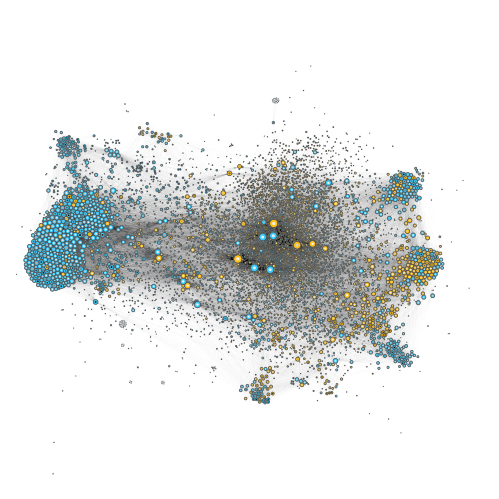

In [ ]:
size_nodes_by = 'degree'
max_node_size = 25

G = networks_uni['directed'].copy()
node_sizes = pd.Series({i:(np.log2(j+2))**1.5 for i,j in G.degree()})
nx.set_node_attributes(G, node_sizes, 'size')
nx.set_node_attributes(G, attributes['is_chiral_color'], 'group')

print(G)
fig = plt.figure(figsize=(12,12), layout='constrained')
stylized_network, config = nw.visualize(G, config={'node_label_color': '#000000', 'node_gravity': 0.0, 
                                'link_alpha': 0.005, 'link_color': '#000000', 'zoom': 0.63, 'node_charge': -24,
                                'scale_node_size_by_strength': False, 'node_size_variation': 1,
                                'node_size': max_node_size, 'link_distance':0, 'node_stroke_width': 2})
fig, ax = nw.draw_netwulf(stylized_network)

a = stylized_network.copy()
a['nodeStrokeWidth'] = 0.0
for i in list(range(len(a['nodes']))):
    a['nodes'][i]['radius'] = a['nodes'][i]['radius'] * 0.4
    a['nodes'][i]['color'] = attributes['gen_color'].loc[a['nodes'][i]['id']]

nw.draw_netwulf(a, fig=fig, ax=ax, draw_links=False)

plt.show()

['C00016', 'C00023', 'C00032', 'C00034', 'C00038', 'C00061', 'C00070', 'C00076', 'C00098', 'C00107', 'C00113', 'C00125', 'C00126', 'C00150', 'C00154', 'C00175', 'C00176', 'C00187', 'C00194', 'C00195', 'C00200', 'C00202', 'C00210', 'C00220', 'C00225', 'C00238', 'C00265', 'C00280', 'C00284', 'C00291', 'C00302', 'C00303', 'C00304', 'C00305', 'C00306', 'C00308', 'C00319', 'C00324', 'C00348', 'C00370', 'C00374', 'C00376', 'C00384', 'C00396', 'C00397', 'C00401', 'C00410', 'C00413', 'C00426', 'C00427', 'C00444', 'C00451', 'C00461', 'C00468', 'C00477', 'C00480', 'C00481', 'C00486', 'C00494', 'C00495', 'C00500', 'C00505', 'C00523', 'C00524', 'C00528', 'C00535', 'C00541', 'C00549', 'C00550', 'C00563', 'C00573', 'C00584', 'C00597', 'C00599', 'C00604', 'C00607', 'C00619', 'C00634', 'C00635', 'C00639', 'C00653', 'C00661', 'C00674', 'C00695', 'C00696', 'C00703', 'C00707', 'C00715', 'C00732', 'C00735', 'C00737', 'C00740', 'C00744', 'C00746', 'C00748', 'C00753', 'C00757', 'C00758', 'C00760', 'C00762',

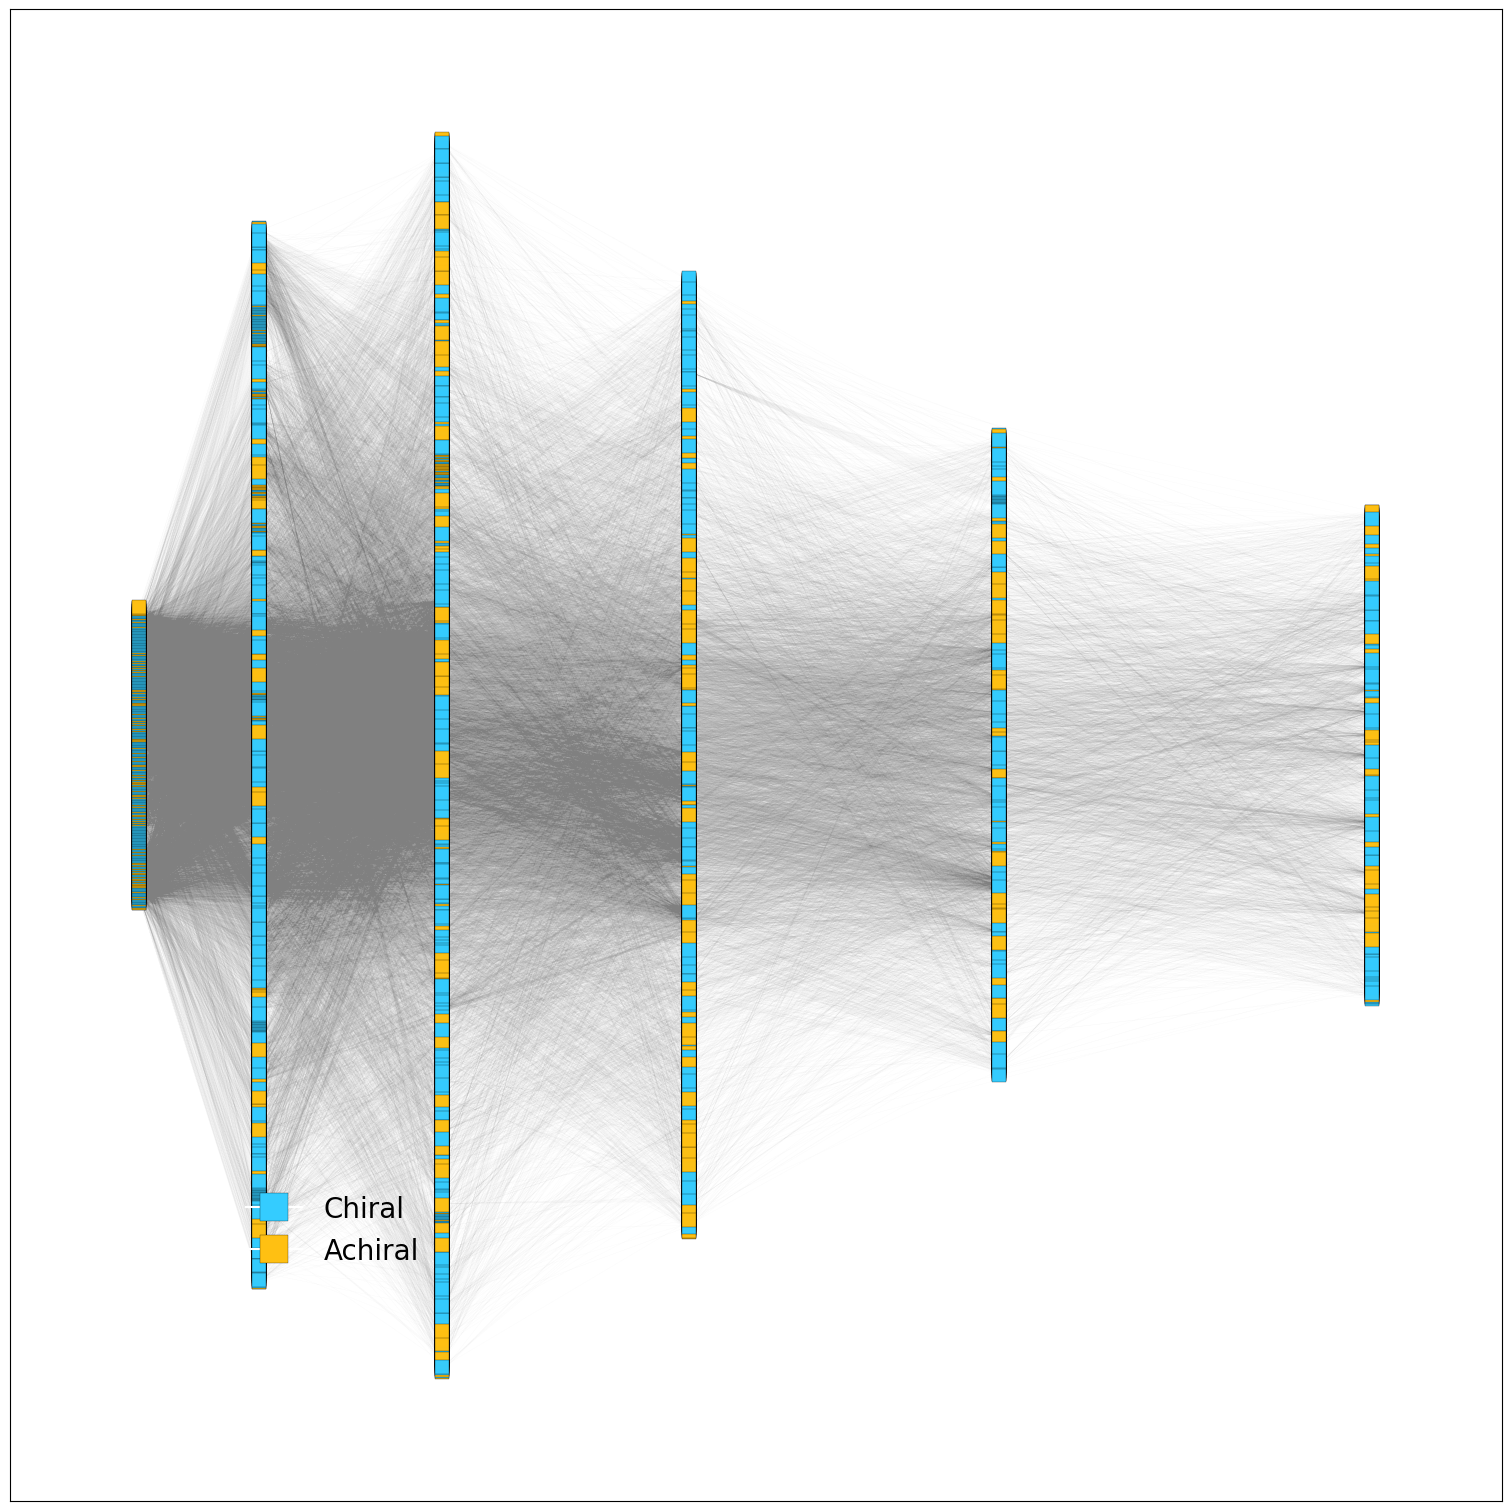

In [ ]:
#attributes['test'] = (attributes['precursor_out_degree_chiral']/(attributes['is_chiral']-0.5)).filter(like='C').sort_values()
#sortby = ['is_chiral', 'test']
show = 'impactful_precursor'
rotate = False

G1 = networks_uni[show] #using impactful_precursor from network generation

#Remove G nodes that are not in attributes df
nodes_to_keep = attributes.index.to_list()
nodes_to_remove = [n for n in nodes_to_keep if n not in G1.nodes()]
print(nodes_to_remove)
G1.remove_nodes_from(nodes_to_remove)

nx.set_node_attributes(G1, attributes['is_chiral_color'], 'is_chiral_color')

if "C21389" in G1.nodes():
    print("Found C21389")
print(G1)

layers = [list(i) for i in attributes.loc[list(G1.nodes())].groupby(by='gen').groups.values()][:-1]
for layer in layers:
    if "C21389" in layer:
        print(f"Found C21389")
    print(layer)
    print(len(layer))


pos = get_multipartite_layout(edges=list(G1.edges), layers=layers, reduce_edge_crossings=True)
#for i in layers[-1]: del pos[i] # remove last layer
for n in pos.keys(): pos[n][0] = (pos[n][0]+0.2)**2 # spread out later gens to reduce extreme angles 
if rotate: pos = {i:j[::-1] for i,j in pos.items()}

print(pos)
#print(pos["C21389"])

fig, ax = plt.subplots(figsize=(15,15), layout='constrained')
nx.draw_networkx(G1.subgraph(pos.keys()), pos=pos, ax=ax, edge_color=[0.5,0.5,0.5,0.5],
                  node_color=list(gna(G1.subgraph(pos.keys()), 'is_chiral_color').values()),  
                  edgecolors='k', width=0.01, arrows=False,
                  linewidths=0.2, node_size=100, node_shape='s', alpha=0.99,
                  with_labels=False)

# nx.draw_networkx_nodes(G1, pos=pos, ax=ax, node_color=list(gna(G1.subgraph(pos.keys()), 'is_chiral_color').values()), 
#                        node_size=100, node_shape='s', alpha=1.00) #draw nodes
# [nx.draw_networkx_edges(G1, pos=pos, arrows=False, width=0.05,
#                         alpha=0.05)] #loop through edges and draw them


plt.legend(loc='lower left', borderpad=8, frameon=False, handles=[plt.Line2D([0], [0], marker='s', color='w', markeredgecolor='k', markeredgewidth=0.2, markerfacecolor='#34CCFF', markersize=20, label='Chiral'),
                    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#FFC012', markeredgecolor='k', markeredgewidth=0.2, markersize=20, label='Achiral')], prop={'size': 20})
#plt.savefig('fig3_expansion_'+show+'_edges_minimal_crossings.svg', format='svg', facecolor='w', edgecolor='w')
plt.show()